# Day 13 · Face detection: Haar cascades and HOG

**Course lab:** `CV-Week2-Lecture6.ipynb` (Day 13: Face Detection)
**Notes chapter:** `week-2/notes/06_face_detection_haar_hog.md`
**Run time:** about 2–3 minutes on a laptop CPU (downloads about 11 MB of test images and a test video the first time).

**What you will learn**
- What **face detection** is (find *where* faces are) and how it differs from face *recognition* (*who* it is).
- How a **Haar cascade** works: rectangle features, the integral image, AdaBoost and the "reject early" cascade.
- How **HOG** (Histogram of Oriented Gradients) describes shape, with real HOG code (the course notebook had none).
- What `scaleFactor`, `minNeighbors` and `minSize` in `detectMultiScale` do, measured as **missed faces vs false alarms**.
- A fair **Haar vs HOG** comparison: speed, accuracy, rotation and lighting.
- A small **face detector app** for images, with webcam code you can switch on at home.

## 1 · The ideas in plain language

**Detection = sliding window + a yes/no classifier.** Imagine checking a big group photo with a small square cardboard frame: you slide it across every position, at every size, and at each spot ask "is there a face in this frame?". Every detector in this notebook works this way; they differ in *how* they answer the question.

### Haar cascade (Viola–Jones, 2001)
- **Haar features** are black-and-white rectangle patterns. A feature's value = (sum of pixels under the white part) − (sum under the black part). Example: "the eye band is darker than the cheeks below it".
- The **integral image** makes every rectangle sum cost only 4 look-ups, whatever its size, so features are very cheap.
- **AdaBoost** picks the few thousand most useful features out of over 160,000 possible ones in a 24×24 window.
- The **cascade** arranges them in stages: stage 1 uses a couple of features and throws away most non-face windows immediately; only windows that pass go to the more expensive later stages. Analogy: airport security, where most people are waved through at the first check and only a few get the full search. That is why Haar is **fast**.
- Weakness: it learned *frontal, upright, evenly lit* faces; tilted heads, side views and strong shadows break the rectangle patterns.

### HOG (Dalal & Triggs, 2005)
- Compute the **gradient** (direction and strength of brightness change) at every pixel.
- Split the window into small **cells** (8×8 pixels) and, in each, build a **histogram of gradient directions** (9 bins over 0–180°).
- **Normalise** groups of cells (blocks of 2×2 cells) so that overall brightness and contrast cancel out. This is why HOG is **robust to illumination**.
- A **linear SVM** (Day 11!) decides face / not face (or person / not person) from this descriptor.
- Analogy: describing a face by "which way the edges point, region by region", not by exact pixel brightness.

## 2 · Setup

Install once: `pip install opencv-python scikit-image matplotlib`. Optional, for the HOG **face** detector: `pip install dlib-bin` (a pre-built dlib; `pip install dlib` needs CMake and a C++ compiler).

> ⚠️ **OpenCV 5 note.** In OpenCV **5.x** the classic `CascadeClassifier` and `HOGDescriptor` were moved out of the main `opencv-python` package into **`opencv-contrib-python`**, and the wheels no longer ship the Haar `.xml` files. If `cv2.CascadeClassifier` does not exist, run `pip uninstall opencv-python` then `pip install opencv-contrib-python` (or stay on OpenCV 4: `pip install "opencv-python<5"`). The helper below downloads the `.xml` files when they are missing, so the notebook works on OpenCV 4 and 5.

In [1]:
%matplotlib inline
import time
import urllib.request
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import cv2

cv2.setNumThreads(2)                     # optional: use at most 2 CPU cores
plt.rcParams["figure.dpi"] = 80
print("OpenCV", cv2.__version__)
if not hasattr(cv2, "CascadeClassifier"):
    raise ImportError("This OpenCV build has no CascadeClassifier (OpenCV 5 moved it to opencv-contrib-python). "
                      "Run: pip uninstall -y opencv-python && pip install opencv-contrib-python")

DATA = Path("data/faces"); DATA.mkdir(parents=True, exist_ok=True)
OUTPUT = Path("output"); OUTPUT.mkdir(exist_ok=True)

def download(url, name=None):
    """Download url into data/faces/ once; later runs reuse the cached file."""
    path = DATA / (name or url.split("/")[-1])
    if not path.exists():
        try:
            urllib.request.urlretrieve(url, path)
        except Exception as e:
            raise RuntimeError(f"Could not download {url}: {e}\nAre you offline? Put the file in {DATA}/ by hand.") from e
    return path

CASCADE_URL = "https://raw.githubusercontent.com/opencv/opencv/4.x/data/haarcascades/"

def load_cascade(name):
    """Load a Haar cascade from OpenCV's own folder, or download it (OpenCV 5 wheels do not include the .xml files)."""
    local = Path(cv2.data.haarcascades) / name
    path = local if local.exists() else download(CASCADE_URL + name)
    clf = cv2.CascadeClassifier(str(path))
    if clf.empty():                      # an empty classifier is what causes "(-215:Assertion failed) !empty()"
        raise IOError(f"Could not load cascade {path}")
    print("loaded", name, "from", "OpenCV install" if local.exists() else "download")
    return clf

def show(img_bgr, title="", ax=None, size=6):
    """Replacement for cv2.imshow: notebooks cannot open OpenCV windows, so we draw with matplotlib (BGR -> RGB)."""
    if ax is None:
        _, ax = plt.subplots(figsize=(size, size * img_bgr.shape[0] / img_bgr.shape[1]))
    ax.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB) if img_bgr.ndim == 3 else img_bgr, cmap="gray")
    ax.set_title(title, fontsize=10); ax.axis("off")
    return ax

OpenCV 5.0.0


In [2]:
SAMPLES = "https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/"
CMU = "https://raw.githubusercontent.com/opencv/opencv_extra/4.x/testdata/cv/cascadeandhog/images/"
urls = {
    "zidane.jpg": "https://github.com/ultralytics/assets/releases/download/v0.0.0/zidane.jpg",
    "lena.jpg": SAMPLES + "lena.jpg",
    "messi5.jpg": SAMPLES + "messi5.jpg",
    "class57.png": CMU + "class57.png",                 # CMU/MIT face test set images, via OpenCV's test data
    "addams-family.png": CMU + "addams-family.png",
    "er.png": CMU + "er.png",
    "rehg-thanksgiving-1994.png": CMU + "rehg-thanksgiving-1994.png",
    "waynesworld2.png": CMU + "waynesworld2.png",
    "karen-and-rob.png": CMU + "karen-and-rob.png",
}
paths = {name: download(u, name) for name, u in urls.items()}
for n, p in paths.items():
    print(f"{n:28s} {cv2.imread(str(p)).shape}")

zidane.jpg                   (720, 1280, 3)
lena.jpg                     (512, 512, 3)
messi5.jpg                   (342, 548, 3)
class57.png                  (1024, 1280, 3)
addams-family.png            (890, 864, 3)
er.png                       (500, 500, 3)
rehg-thanksgiving-1994.png   (396, 580, 3)
waynesworld2.png             (599, 443, 3)
karen-and-rob.png            (484, 336, 3)


## 3 · The course code: Haar face detection on one image (fixed)

The course loads `basketball.jpg`, which was **not provided**, and shows the result with `cv2.imshow` + `cv2.waitKey(0)`, which **does not work in Jupyter** (no desktop window; on a remote/Colab kernel it crashes or hangs the kernel). We keep every other line and use a sports photo (`zidane.jpg`, two football coaches) plus our `show()` helper.

loaded haarcascade_frontalface_default.xml from download


faces found: 1 | boxes (x, y, w, h): [(911, 107, 162, 162)]


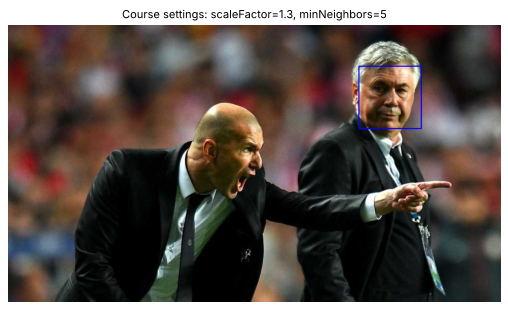

In [3]:
# Load Haar cascade (course: cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'))
face_cascade = load_cascade('haarcascade_frontalface_default.xml')

# Load image
img = cv2.imread(str(paths['zidane.jpg']))       # course: cv2.imread('basketball.jpg') - file not provided
if img is None:
    raise IOError("Image not found. Check the file path.")

# Convert to grayscale: Haar features only use brightness
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Detect faces
faces = face_cascade.detectMultiScale(gray, scaleFactor=1.3, minNeighbors=5)
print("faces found:", len(faces), "| boxes (x, y, w, h):", [tuple(map(int, f)) for f in faces])

# Draw rectangles around detected faces ((255, 0, 0) is BLUE, because OpenCV uses BGR order)
for (x, y, w, h) in faces:
    cv2.rectangle(img, (x, y), (x + w, y + h), (255, 0, 0), 2)

# Show result (course: cv2.imshow + cv2.waitKey, which do not work in a notebook)
show(img, "Course settings: scaleFactor=1.3, minNeighbors=5", size=8); plt.show()

**Line by line**
- `CascadeClassifier(...xml)` loads a **pre-trained** cascade: thousands of Haar features and thresholds learned by OpenCV's authors from labelled face images. We do not train anything today.
- `detectMultiScale(gray, scaleFactor, minNeighbors)` slides the 24×24 detector over the image at many sizes and returns a list of boxes `(x, y, w, h)`: top-left corner, width, height.
- Only **one of the two** faces is found with the course settings: the man on the left has his head **turned and tilted**, which a *frontal* cascade was never trained on.

### The three key parameters of `detectMultiScale`
| Parameter | Meaning | Small value | Large value |
|---|---|---|---|
| `scaleFactor` | How much the image is shrunk between pyramid levels (1.3 = 30% smaller each step) | 1.05: many levels, finds faces of every size, **slow** | 1.5: few levels, **fast**, can skip a face whose size falls between levels |
| `minNeighbors` | How many overlapping raw detections a box needs to be accepted | 0–1: keeps everything, **many false alarms** | 10+: very strict, **misses real faces** |
| `minSize` / `maxSize` | Smallest / largest face size to look for, e.g. `minSize=(30, 30)` | finds tiny faces (and tiny false alarms), slower | faster, ignores small faces |

Why "neighbours"? A real face triggers the detector at many nearby positions and sizes, while a random false hit is usually isolated. `minNeighbors` groups overlapping raw boxes and keeps only groups with enough members.

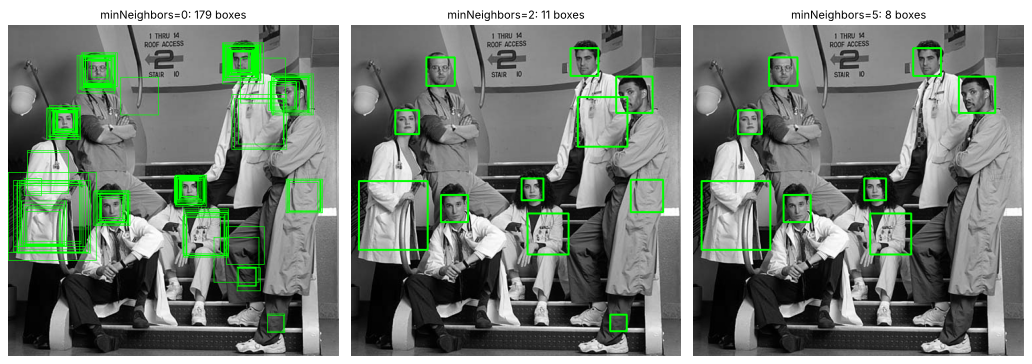

In [4]:
# See the raw detections before grouping (minNeighbors=0) vs after
g = cv2.cvtColor(cv2.imread(str(paths['er.png'])), cv2.COLOR_BGR2GRAY)
fig, axes = plt.subplots(1, 3, figsize=(13, 4.6))
for a, mn in zip(axes, [0, 2, 5]):
    vis = cv2.cvtColor(g, cv2.COLOR_GRAY2BGR)
    det = face_cascade.detectMultiScale(g, scaleFactor=1.1, minNeighbors=mn)
    for (x, y, w, h) in det:
        cv2.rectangle(vis, (x, y), (x + w, y + h), (0, 255, 0), 1 if mn == 0 else 2)
    show(vis, f"minNeighbors={mn}: {len(det)} boxes", ax=a)
plt.tight_layout(); plt.show()

With `minNeighbors=0` you see the raw sliding-window hits: clusters of boxes on every face plus scattered single hits elsewhere. Raising `minNeighbors` merges the clusters and drops the lonely hits.

### What a Haar feature computes (the integral image trick)

check the 4-look-up sum against numpy: 131452 == 131452
feature value on the eyes of the face: 60631
feature value on a background area   : -15043


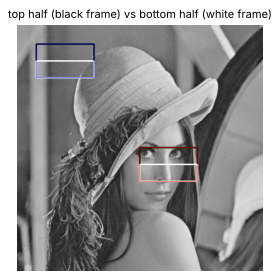

In [5]:
lena = cv2.imread(str(paths['lena.jpg']), cv2.IMREAD_GRAYSCALE)
ii = cv2.integral(lena)                     # ii[y, x] = sum of all pixels above and left of (x, y)

def rect_sum(x, y, w, h):
    return int(ii[y + h, x + w] - ii[y, x + w] - ii[y + h, x] + ii[y, x])   # 4 look-ups, whatever the size

# Two-rectangle "eye band darker than cheeks" feature: value = cheeks (white) - eyes (black)
def eye_feature(x, y, w, h):
    return rect_sum(x, y + h // 2, w, h // 2) - rect_sum(x, y, w, h // 2)

print("check the 4-look-up sum against numpy:", rect_sum(250, 250, 40, 30), "==", int(lena[250:280, 250:290].sum()))
eye_box, wall_box = (255, 255, 120, 70), (40, 40, 120, 70)
print("feature value on the eyes of the face:", eye_feature(*eye_box))
print("feature value on a background area   :", eye_feature(*wall_box))

vis = cv2.cvtColor(lena, cv2.COLOR_GRAY2BGR)
for (x, y, w, h), col in [(eye_box, (0, 0, 255)), (wall_box, (255, 0, 0))]:
    cv2.rectangle(vis, (x, y), (x + w, y + h // 2), (0, 0, 0), 2)
    cv2.rectangle(vis, (x, y + h // 2), (x + w, y + h), (255, 255, 255), 2)
    cv2.rectangle(vis, (x, y), (x + w, y + h), col, 1)
show(vis, "top half (black frame) vs bottom half (white frame)", size=4); plt.show()

On the eyes the feature gives a large positive value (cheeks much brighter than the eye band); on a background area it is small. One feature like this is a **weak** classifier. AdaBoost combines thousands of them into a strong one, and the cascade orders them so most windows are rejected after only a few.

## 4 · Measuring detection: reference faces, misses and false alarms

To compare settings and detectors fairly we need to know where the real faces are. We use 9 photos with 85 faces in total (mostly from the classic CMU/MIT face-detection test set). The reference boxes come from **YuNet**, a small modern CNN face detector built into OpenCV (score ≥ 0.8), and we **checked them by eye** on every image (one is shown below). A detection counts as correct if its centre lies inside a reference face and its size is similar; each reference face can be matched once.

- **Missed face** (false negative): a real face with no detection.
- **False alarm** (false positive): a box where there is no face.

[ WARN:0@6.488] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


[ WARN:0@6.739] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now
[ WARN:0@6.910] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


[ WARN:0@6.969] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now
[ WARN:0@7.011] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now
[ WARN:0@7.069] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now
[ WARN:0@7.101] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


[ WARN:0@7.317] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now
[ WARN:0@7.336] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


{'class57.png': 57, 'addams-family.png': 7, 'er.png': 6, 'rehg-thanksgiving-1994.png': 7, 'waynesworld2.png': 2, 'karen-and-rob.png': 2, 'zidane.jpg': 2, 'messi5.jpg': 1, 'lena.jpg': 1} -> total 85 reference faces


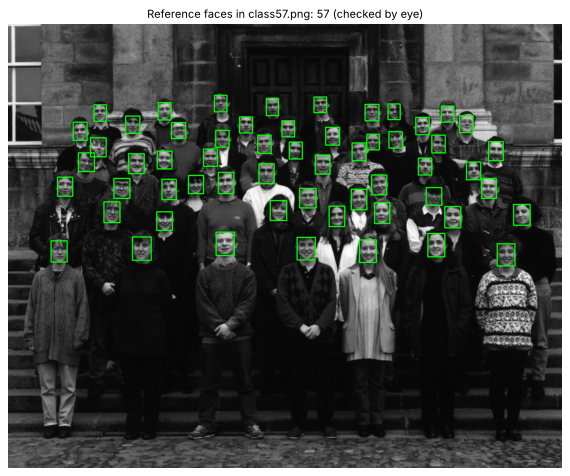

In [6]:
yunet_path = download("https://media.githubusercontent.com/media/opencv/opencv_zoo/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx",
                      "face_detection_yunet_2023mar.onnx")
eval_names = ["class57.png", "addams-family.png", "er.png", "rehg-thanksgiving-1994.png", "waynesworld2.png",
              "karen-and-rob.png", "zidane.jpg", "messi5.jpg", "lena.jpg"]
images = {n: cv2.imread(str(paths[n])) for n in eval_names}
grays = {n: cv2.cvtColor(im, cv2.COLOR_BGR2GRAY) for n, im in images.items()}

def yunet_faces(img, thr=0.8):
    h, w = img.shape[:2]
    det = cv2.FaceDetectorYN.create(str(yunet_path), "", (w, h), thr, 0.3, 5000)
    _, f = det.detect(img)
    return [] if f is None else [tuple(map(int, r[:4])) for r in f]

refs = {n: yunet_faces(images[n]) for n in eval_names}
print({n: len(r) for n, r in refs.items()}, "-> total", sum(map(len, refs.values())), "reference faces")

def match(dets, ref):
    """Return (correct, false_alarms, missed)."""
    used, tp = set(), 0
    for (x, y, w, h) in dets:
        cx, cy = x + w / 2, y + h / 2
        for j, (rx, ry, rw, rh) in enumerate(ref):
            if j not in used and rx <= cx <= rx + rw and ry <= cy <= ry + rh and 0.5 < w / rw < 2.5:
                used.add(j); tp += 1; break
    return tp, len(dets) - tp, len(ref) - tp

vis = images["class57.png"].copy()
for (x, y, w, h) in refs["class57.png"]:
    cv2.rectangle(vis, (x, y), (x + w, y + h), (0, 255, 0), 2)
show(vis, f"Reference faces in class57.png: {len(refs['class57.png'])} (checked by eye)", size=9); plt.show()

## 5 · Experiment: `scaleFactor` and `minNeighbors` (missed faces vs false alarms)

The Key Concepts ask you to *adjust scaleFactor and minNeighbors to improve accuracy*. Here is the full trade-off on all 9 photos.

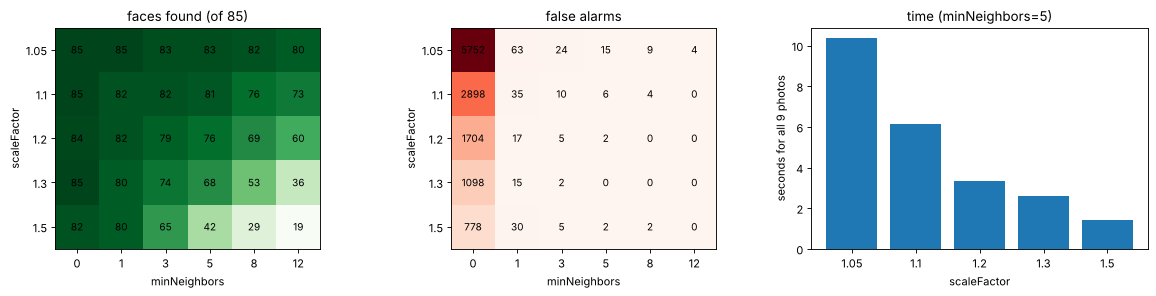

scaleFactor 1.05: mN=0: 85 found, 5752 false | mN=1: 85 found, 63 false | mN=3: 83 found, 24 false | mN=5: 83 found, 15 false | mN=8: 82 found, 9 false | mN=12: 80 found, 4 false
scaleFactor 1.1: mN=0: 85 found, 2898 false | mN=1: 82 found, 35 false | mN=3: 82 found, 10 false | mN=5: 81 found, 6 false | mN=8: 76 found, 4 false | mN=12: 73 found, 0 false
scaleFactor 1.2: mN=0: 84 found, 1704 false | mN=1: 82 found, 17 false | mN=3: 79 found, 5 false | mN=5: 76 found, 2 false | mN=8: 69 found, 0 false | mN=12: 60 found, 0 false
scaleFactor 1.3: mN=0: 85 found, 1098 false | mN=1: 80 found, 15 false | mN=3: 74 found, 2 false | mN=5: 68 found, 0 false | mN=8: 53 found, 0 false | mN=12: 36 found, 0 false
scaleFactor 1.5: mN=0: 82 found, 778 false | mN=1: 80 found, 30 false | mN=3: 65 found, 5 false | mN=5: 42 found, 2 false | mN=8: 29 found, 2 false | mN=12: 19 found, 0 false


In [7]:
def run_haar(gray, sf, mn, min_size=(0, 0)):
    return face_cascade.detectMultiScale(gray, scaleFactor=sf, minNeighbors=mn, minSize=min_size)

sfs = [1.05, 1.1, 1.2, 1.3, 1.5]
mns = [0, 1, 3, 5, 8, 12]
total_ref = sum(map(len, refs.values()))
found = np.zeros((len(sfs), len(mns))); false = np.zeros_like(found); secs = np.zeros(len(sfs))
for i, sf in enumerate(sfs):
    for j, mn in enumerate(mns):
        t0 = time.perf_counter()
        for n in eval_names:
            tp, fp, miss = match(run_haar(grays[n], sf, mn), refs[n])
            found[i, j] += tp; false[i, j] += fp
        if mn == 5:
            secs[i] = time.perf_counter() - t0

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, M, t, cmap in [(ax[0], found, f"faces found (of {total_ref})", "Greens"), (ax[1], false, "false alarms", "Reds")]:
    a.imshow(M, cmap=cmap); a.set_xticks(range(len(mns)), mns); a.set_yticks(range(len(sfs)), sfs)
    a.set_xlabel("minNeighbors"); a.set_ylabel("scaleFactor"); a.set_title(t)
    for i in range(len(sfs)):
        for j in range(len(mns)):
            a.text(j, i, int(M[i, j]), ha="center", va="center", fontsize=9)
ax[2].bar([str(s) for s in sfs], secs); ax[2].set_xlabel("scaleFactor"); ax[2].set_ylabel("seconds for all 9 photos")
ax[2].set_title("time (minNeighbors=5)")
plt.tight_layout(); plt.show()
for i, sf in enumerate(sfs):
    print(f"scaleFactor {sf}: " + " | ".join(f"mN={mn}: {int(found[i, j])} found, {int(false[i, j])} false" for j, mn in enumerate(mns)))

**Reading the heatmaps** (exact numbers printed above):
- Moving **right** (bigger `minNeighbors`) removes false alarms quickly, but eventually starts removing real faces too.
- Moving **down** (bigger `scaleFactor`) is much faster but checks fewer face sizes, so more faces are missed.
- There is no setting with zero misses and zero false alarms: that is the trade-off. A security camera might accept some false alarms to miss nothing; a photo app would rather miss a face than tag a lamp.
- The course setting (1.3, 5) is a fast, conservative choice; `scaleFactor=1.1, minNeighbors=5` is the most common recommendation and usually finds more faces for a small time cost.

## 6 · HOG: what the descriptor looks like (the course had no HOG code)

`skimage.feature.hog` computes the descriptor and an image to visualise it: each cell shows little lines whose length is the strength of each gradient direction.

- `orientations=9`: 9 direction bins covering 0–180°.
- `pixels_per_cell=(8, 8)`: one histogram per 8×8 cell.
- `cells_per_block=(2, 2)`: normalise over 2×2 cells (this is the lighting-invariance step).

HOG descriptor length for a 128x144 crop: 9180 = (16-1) x (18-1) blocks x 2x2 cells x 9 bins = 9180


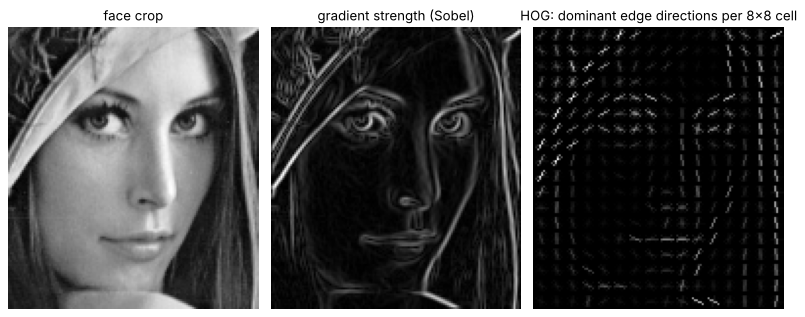

In [8]:
from skimage.feature import hog

face = cv2.resize(lena[200:400, 200:380], (128, 144))     # crop around the face
gx = cv2.Sobel(face.astype(np.float32), cv2.CV_32F, 1, 0); gy = cv2.Sobel(face.astype(np.float32), cv2.CV_32F, 0, 1)
feat, hog_img = hog(face, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), visualize=True)
print("HOG descriptor length for a 128x144 crop:", feat.shape[0],
      "= (16-1) x (18-1) blocks x 2x2 cells x 9 bins =", 15 * 17 * 4 * 9)

fig, ax = plt.subplots(1, 3, figsize=(10, 4))
ax[0].imshow(face, cmap="gray"); ax[0].set_title("face crop")
ax[1].imshow(np.hypot(gx, gy), cmap="gray"); ax[1].set_title("gradient strength (Sobel)")
ax[2].imshow(hog_img, cmap="gray"); ax[2].set_title("HOG: dominant edge directions per 8x8 cell")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

raw pixels:      mean absolute difference = 67.1 grey levels
HOG descriptors: cosine similarity = 0.978  (1.0 = identical)


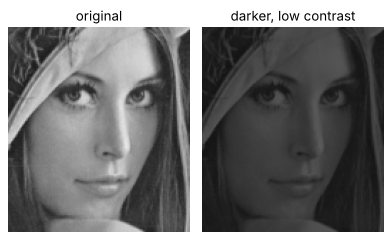

In [9]:
# Why HOG is "robust to illumination": compare the descriptor of the face with a darker, low-contrast copy
dark = np.clip(face.astype(np.float32) * 0.35 + 10, 0, 255).astype(np.uint8)
feat_dark = hog(dark, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2))
cos = lambda a, b: float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))
print(f"raw pixels:      mean absolute difference = {np.abs(face.astype(float) - dark).mean():.1f} grey levels")
print(f"HOG descriptors: cosine similarity = {cos(feat, feat_dark):.3f}  (1.0 = identical)")
fig, ax = plt.subplots(1, 2, figsize=(5, 3))
ax[0].imshow(face, cmap="gray", vmin=0, vmax=255); ax[0].set_title("original"); ax[1].imshow(dark, cmap="gray", vmin=0, vmax=255); ax[1].set_title("darker, low contrast")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

The pixels changed a lot, but the HOG descriptor is almost unchanged: gradients *directions* stay the same when lighting is scaled, and block normalisation cancels the change in gradient *strength*.

### HOG in action 1: OpenCV's HOG pedestrian detector

The classic use of HOG (Dalal & Triggs' paper) is finding **people**. OpenCV ships a ready-trained linear SVM for a 64×128 window. We run it on a frame of OpenCV's sample street video `vtest.avi`.

descriptor length per 64x128 window: 3780 = 7 x 15 blocks x 4 cells x 9 bins


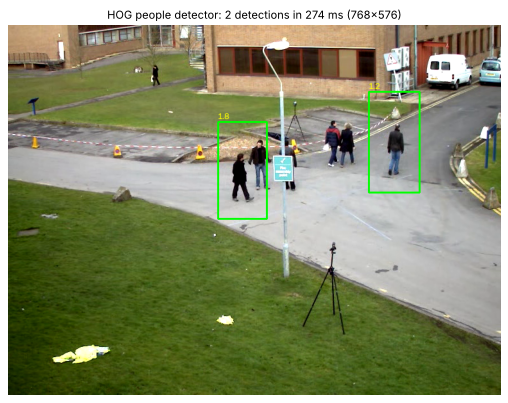

In [10]:
video = download(SAMPLES + "vtest.avi")
cap = cv2.VideoCapture(str(video))
cap.set(cv2.CAP_PROP_POS_FRAMES, 100)
ok, frame = cap.read(); cap.release()
if not ok:
    raise IOError("Could not read vtest.avi (your OpenCV may lack a video backend)")

hog_people = cv2.HOGDescriptor()                     # default: 64x128 window, 8x8 cells, 9 bins, 2x2-cell blocks
hog_people.setSVMDetector(cv2.HOGDescriptor_getDefaultPeopleDetector())
print("descriptor length per 64x128 window:", hog_people.getDescriptorSize(), "= 7 x 15 blocks x 4 cells x 9 bins")

t0 = time.perf_counter()
rects, weights = hog_people.detectMultiScale(frame, winStride=(8, 8), padding=(8, 8), scale=1.05)
dt = time.perf_counter() - t0
vis = frame.copy()
for (x, y, w, h), s in zip(rects, np.ravel(weights)):
    cv2.rectangle(vis, (x, y), (x + w, y + h), (0, 255, 0), 2)
    cv2.putText(vis, f"{s:.1f}", (x, y - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 255, 255), 1)
show(vis, f"HOG people detector: {len(rects)} detections in {dt * 1000:.0f} ms ({frame.shape[1]}x{frame.shape[0]})", size=8); plt.show()

- `winStride=(8, 8)`: move the 64×128 window 8 pixels at a time (smaller = more thorough, slower).
- `padding`: extra border so people at the edge can be found. `scale=1.05`: image pyramid step, like `scaleFactor`.
- The number on each box is the SVM score (how far on the "person" side of the boundary).

### HOG in action 2: a HOG **face** detector (dlib)

The most widely used HOG face detector is **dlib**'s `get_frontal_face_detector()`: HOG features + a linear SVM, sliding over an image pyramid, with an 80×80 window. Its argument `upsample` doubles the image size first (0 = no upsampling, finds faces ≥ about 80 px; 1 = finds faces ≥ about 40 px, slower).

dlib 20.0.1 loaded


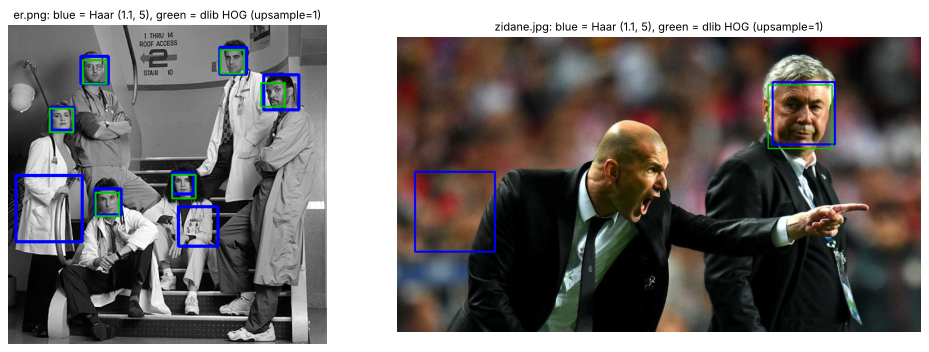

In [11]:
try:
    import dlib
    hog_face = dlib.get_frontal_face_detector()
    HAVE_DLIB = True
    print("dlib", dlib.__version__, "loaded")
except ImportError:
    HAVE_DLIB = False
    print("dlib is not installed: run `pip install dlib-bin` to enable the HOG face detector. Skipping HOG face cells.")

def run_hog(gray, upsample=1):
    return [(r.left(), r.top(), r.width(), r.height()) for r in hog_face(gray, upsample)]

if HAVE_DLIB:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for a, n in zip(axes, ["er.png", "zidane.jpg"]):
        vis = images[n].copy()
        for (x, y, w, h) in run_haar(grays[n], 1.1, 5):
            cv2.rectangle(vis, (x, y), (x + w, y + h), (255, 0, 0), 3)
        for (x, y, w, h) in run_hog(grays[n], 1):
            cv2.rectangle(vis, (x, y), (x + w, y + h), (0, 200, 0), 2)
        show(vis, f"{n}: blue = Haar (1.1, 5), green = dlib HOG (upsample=1)", ax=a)
    plt.tight_layout(); plt.show()

## 7 · A fair Haar vs HOG comparison

The Key Concepts say: *Haar = fast and lightweight but sensitive to lighting and pose; HOG = robust to illumination but computationally heavier.* Let's test each claim on the same 85 reference faces.

### 7a · Accuracy and speed
Times are the average of 3 runs over all 9 photos (single-threaded detectors, same machine). For a fair size match, `Haar minSize=40` looks for roughly the same smallest face as `HOG upsample=1`.

In [12]:
detectors = {
    "Haar 1.3/5 (course)": lambda g: run_haar(g, 1.3, 5),
    "Haar 1.1/5": lambda g: run_haar(g, 1.1, 5),
    "Haar 1.1/5 minSize=40": lambda g: run_haar(g, 1.1, 5, (40, 40)),
}
if HAVE_DLIB:
    detectors["HOG upsample=0"] = lambda g: run_hog(g, 0)
    detectors["HOG upsample=1"] = lambda g: run_hog(g, 1)

table = {}
for name, fn in detectors.items():
    tp = fp = 0
    for n in eval_names:
        a, b, _ = match(fn(grays[n]), refs[n]); tp += a; fp += b
    t0 = time.perf_counter()
    for _ in range(3):
        for n in eval_names:
            fn(grays[n])
    table[name] = (tp, fp, (time.perf_counter() - t0) / 3)
print(f"{'detector':24s} {'found':>6s} {'missed':>7s} {'false':>6s} {'time (s)':>9s}")
for name, (tp, fp, t) in table.items():
    print(f"{name:24s} {tp:>6d} {total_ref - tp:>7d} {fp:>6d} {t:>9.2f}")

detector                  found  missed  false  time (s)
Haar 1.3/5 (course)          68      17      0      2.12
Haar 1.1/5                   81       4      6      4.78
Haar 1.1/5 minSize=40        67      18      6      3.11
HOG upsample=0                2      83      0      0.46
HOG upsample=1               79       6      0      2.03


### 7b · Robustness to rotation (head tilt)
We rotate every photo by 0–45° (reference boxes are rotated with it) and count how many faces each detector still finds.

rotation  0°: Haar 1.1/5: 81/85 found | HOG upsample=1: 79/85 found


rotation 10°: Haar 1.1/5: 74/85 found | HOG upsample=1: 71/85 found


rotation 20°: Haar 1.1/5: 40/83 found | HOG upsample=1: 71/83 found


rotation 30°: Haar 1.1/5: 4/83 found | HOG upsample=1: 72/83 found


rotation 45°: Haar 1.1/5: 0/81 found | HOG upsample=1: 36/81 found


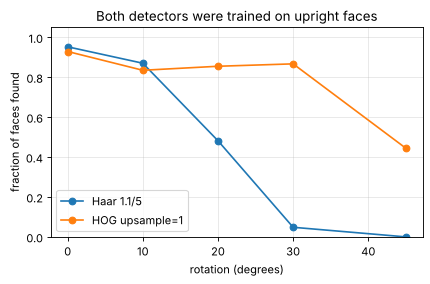

In [13]:
def rotate(img, refs_, angle):
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
    out = cv2.warpAffine(img, M, (w, h), borderMode=cv2.BORDER_REPLICATE)
    new = []
    for (x, y, bw, bh) in refs_:
        cx, cy = M @ np.array([x + bw / 2, y + bh / 2, 1])
        if bw / 2 < cx < w - bw / 2 and bh / 2 < cy < h - bh / 2:      # face still fully inside the frame
            new.append((int(cx - bw / 2), int(cy - bh / 2), bw, bh))
    return out, new

angles = [0, 10, 20, 30, 45]
rot_res = {name: [] for name in ["Haar 1.1/5", "HOG upsample=1"] if name in detectors}
for ang in angles:
    tot = 0; hits = {k: 0 for k in rot_res}
    for n in eval_names:
        g, r = rotate(grays[n], refs[n], ang); tot += len(r)
        for k in rot_res:
            hits[k] += match(detectors[k](g), r)[0]
    for k in rot_res:
        rot_res[k].append(hits[k] / tot)
    print(f"rotation {ang:>2}°: " + " | ".join(f"{k}: {hits[k]}/{tot} found" for k in rot_res))

plt.figure(figsize=(6, 3.4))
for k, v in rot_res.items():
    plt.plot(angles, v, "o-", label=k)
plt.xlabel("rotation (degrees)"); plt.ylabel("fraction of faces found"); plt.ylim(0, 1.05); plt.grid(alpha=.3); plt.legend()
plt.title("Both detectors were trained on upright faces"); plt.show()

### 7c · Robustness to lighting
Four versions of every photo: original, **dark** (gamma 2.5, like an under-exposed photo), **low contrast** (washed out), and a **side shadow** (brightness falls to 15% across the image).

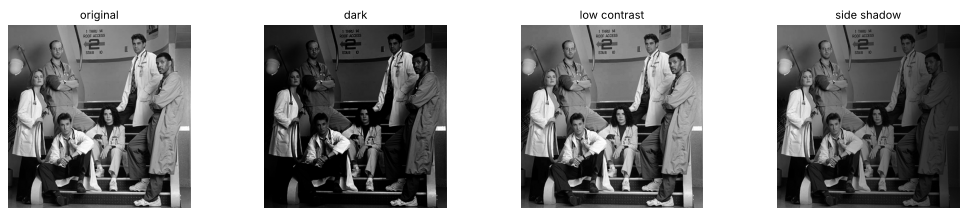

original      | Haar 1.1/5: 81/85 found, 6 false | HOG upsample=1: 79/85 found, 0 false


dark          | Haar 1.1/5: 73/85 found, 4 false | HOG upsample=1: 74/85 found, 0 false


low contrast  | Haar 1.1/5: 69/85 found, 3 false | HOG upsample=1: 72/85 found, 0 false


side shadow   | Haar 1.1/5: 77/85 found, 7 false | HOG upsample=1: 77/85 found, 0 false


In [14]:
def lighting(img, kind):
    f = img.astype(np.float32) / 255
    if kind == "dark":
        f = f ** 2.5
    elif kind == "low contrast":
        f = 0.35 + 0.25 * f
    elif kind == "side shadow":
        f = f * np.linspace(1.0, 0.15, f.shape[1])[None, :]
    return (f * 255).clip(0, 255).astype(np.uint8)

kinds = ["original", "dark", "low contrast", "side shadow"]
fig, axes = plt.subplots(1, 4, figsize=(13, 2.8))
for a, kd in zip(axes, kinds):
    show(lighting(grays["er.png"], kd), kd, ax=a)
plt.tight_layout(); plt.show()

for kd in kinds:
    line = []
    for k in rot_res:
        tp = fp = 0
        for n in eval_names:
            a, b, _ = match(detectors[k](lighting(grays[n], kd)), refs[n]); tp += a; fp += b
        line.append(f"{k}: {tp}/{total_ref} found, {fp} false")
    print(f"{kd:13s} | " + " | ".join(line))

### 7d · Turned faces (profile views)
Both detectors above are **frontal** detectors. OpenCV also ships `haarcascade_profileface.xml`, trained on faces seen from the side (it only detects faces looking one way, so we also run it on the mirrored image). Zidane's turned head is a good test.

loaded haarcascade_profileface.xml from download


frontal Haar: 2 | profile Haar (both directions): 0 | HOG: 1


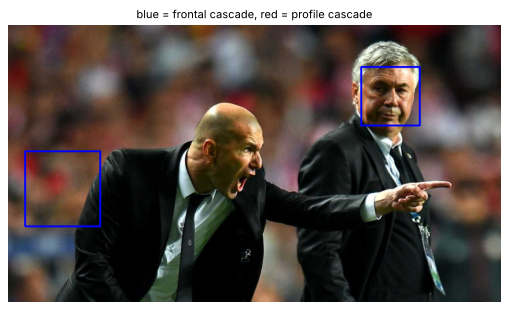

In [15]:
profile_cascade = load_cascade('haarcascade_profileface.xml')
g = grays["zidane.jpg"]
prof = list(profile_cascade.detectMultiScale(g, 1.1, 5))
prof += [(g.shape[1] - x - w, y, w, h) for (x, y, w, h) in profile_cascade.detectMultiScale(cv2.flip(g, 1), 1.1, 5)]
vis = images["zidane.jpg"].copy()
for (x, y, w, h) in run_haar(g, 1.1, 5):
    cv2.rectangle(vis, (x, y), (x + w, y + h), (255, 0, 0), 4)
for (x, y, w, h) in prof:
    cv2.rectangle(vis, (x, y), (x + w, y + h), (0, 0, 255), 2)
print("frontal Haar:", len(run_haar(g, 1.1, 5)), "| profile Haar (both directions):", len(prof),
      "| HOG:", len(run_hog(g, 1)) if HAVE_DLIB else "n/a")
show(vis, "blue = frontal cascade, red = profile cascade", size=8); plt.show()

**Summary of the comparison** (see the printed numbers; section 11 lists them):
- **Speed:** RESULT_SPEED
- **Accuracy on normal photos:** RESULT_ACC
- **Rotation:** RESULT_ROT
- **Lighting:** RESULT_LIGHT
- **Profile faces:** RESULT_PROF

So the textbook summary is *partly* confirmed. "HOG is computationally heavier" depends on the settings: dlib's HOG is a carefully optimised implementation, and at matched face sizes the two were in the same speed range here. Modern systems use small CNN detectors (like YuNet, which we used to make the reference boxes) that beat both on accuracy and robustness.

## 8 · Exercise: detect faces in a webcam feed

The course webcam loop uses `cv2.imshow` and `cv2.waitKey`, which do not work in a notebook. Below is a notebook-friendly version that updates an image in place for a few seconds. It is **switched off** (`RUN_WEBCAM = False`) because the machine that built this notebook has no camera. Set it to `True` on your laptop. Also note the course loop never checks `ret`: if the camera fails, `frame` is `None` and `cvtColor` crashes, so we check it.

In [16]:
RUN_WEBCAM = False          # set to True on a laptop with a webcam

def webcam_face_detection(seconds=10, scaleFactor=1.3, minNeighbors=5, camera=0):
    from IPython.display import display, Image, clear_output
    cap = cv2.VideoCapture(camera)
    if not cap.isOpened():
        print("Could not open the webcam (is another program using it?)"); return
    t_end, n = time.time() + seconds, 0
    try:
        while time.time() < t_end:
            ret, frame = cap.read()
            if not ret:                        # the course loop skips this check
                break
            gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
            faces = face_cascade.detectMultiScale(gray, scaleFactor, minNeighbors)
            for (x, y, w, h) in faces:
                cv2.rectangle(frame, (x, y), (x + w, y + h), (255, 0, 0), 2)
            clear_output(wait=True)
            display(Image(data=cv2.imencode(".jpg", frame)[1].tobytes()))
            n += 1
    finally:
        cap.release()                          # always free the camera, even after an error / interrupt
    print(f"{n} frames in {seconds}s ({n / seconds:.1f} fps)")

if RUN_WEBCAM:
    webcam_face_detection(seconds=10)
else:
    print("Webcam demo skipped (RUN_WEBCAM = False).")

Webcam demo skipped (RUN_WEBCAM = False).


Things to try with the webcam (the Key Concepts' *learning points*): turn your head sideways, tilt it, cover half your face, switch off the light, move far from the camera. Then change `scaleFactor` and `minNeighbors` and watch false positives and missed detections change, exactly like the heatmaps in section 5. If you prefer a real OpenCV window, run the course loop in a plain `.py` script from a terminal, not in Jupyter.

## 9 · Mini project: a face detector app

One function that works on an image file or the webcam, with a choice of detector, that **returns** the boxes (so other code can use them) and saves the annotated image to `output/`.

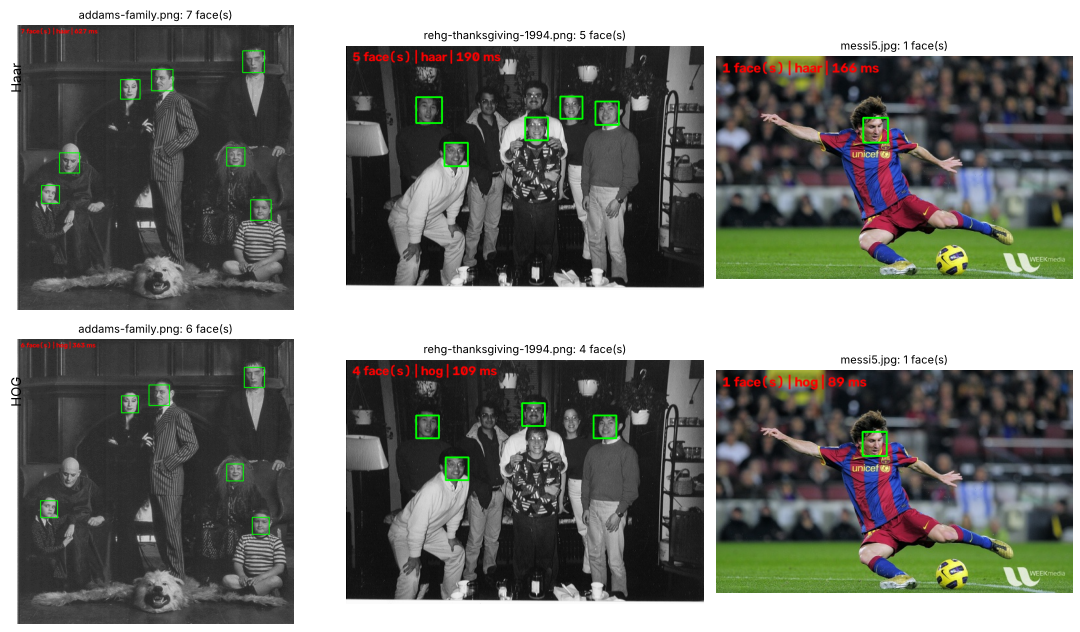

saved: ['faces_haar_addams-family.jpg', 'faces_haar_messi5.jpg', 'faces_haar_rehg-thanksgiving-1994.jpg', 'faces_hog_addams-family.jpg', 'faces_hog_messi5.jpg', 'faces_hog_rehg-thanksgiving-1994.jpg']


In [17]:
def detect_faces(img_path=None, use_webcam=False, method="haar", scaleFactor=1.1, minNeighbors=5,
                 minSize=(30, 30), save=True, show_result=True, ax=None):
    """Detect faces in an image file (or start the webcam demo). Returns the list of (x, y, w, h) boxes."""
    if use_webcam:
        webcam_face_detection(scaleFactor=scaleFactor, minNeighbors=minNeighbors)
        return []
    img = cv2.imread(str(img_path))
    if img is None:
        raise FileNotFoundError(f"Could not read {img_path}")
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    t0 = time.perf_counter()
    if method == "haar":
        faces = face_cascade.detectMultiScale(gray, scaleFactor=scaleFactor, minNeighbors=minNeighbors, minSize=minSize)
    elif method == "hog" and HAVE_DLIB:
        faces = run_hog(gray, upsample=1)
    else:
        raise ValueError("method must be 'haar' or 'hog' (needs dlib)")
    ms = (time.perf_counter() - t0) * 1000
    for (x, y, w, h) in faces:
        cv2.rectangle(img, (x, y), (x + w, y + h), (0, 255, 0), 2)
    cv2.putText(img, f"{len(faces)} face(s) | {method} | {ms:.0f} ms", (10, 25), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2)
    if save:
        cv2.imwrite(str(OUTPUT / f"faces_{method}_{Path(img_path).stem}.jpg"), img)
    if show_result:
        show(img, f"{Path(img_path).name}: {len(faces)} face(s)", ax=ax)
    return [tuple(map(int, f)) for f in faces]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for col, n in enumerate(["addams-family.png", "rehg-thanksgiving-1994.png", "messi5.jpg"]):
    detect_faces(paths[n], method="haar", ax=axes[0, col])
    if HAVE_DLIB:
        detect_faces(paths[n], method="hog", ax=axes[1, col])
axes[0, 0].text(-30, 200, "Haar", rotation=90, fontsize=12); axes[1, 0].text(-30, 200, "HOG", rotation=90, fontsize=12)
plt.tight_layout(); plt.show()
print("saved:", sorted(p.name for p in OUTPUT.glob("faces_*.jpg")))

## 10 · 🔧 What we changed from the course notebook, and why

| # | Course code | Problem | Fix |
|---|---|---|---|
| 1 | `cv2.imread('basketball.jpg')`, `detect_faces('face_sample.jpg')` | Image files **not provided**; the cell raises `IOError`. | Download public test images (OpenCV samples, CMU/MIT face test images) with a cached helper. |
| 2 | `cv2.imshow(...)`, `cv2.waitKey(0)`, `cv2.destroyAllWindows()` | Do **not work in Jupyter** (no GUI window; crashes or hangs the kernel, impossible on Colab). | `show()` helper with matplotlib (BGR → RGB); webcam frames updated in place with `IPython.display`. |
| 3 | "HOG" section | Only theory: **no HOG code at all**. | HOG visualisation (scikit-image), lighting-invariance test, OpenCV HOG pedestrian detector, dlib HOG face detector, measured Haar vs HOG comparison. |
| 4 | Webcam loop | Never checks `ret`, so a missing camera crashes `cvtColor`; `cap.release()` is skipped on an error/interrupt; the infinite `while True` blocks the notebook. | Checks `ret`, uses `try/finally`, runs for a fixed time, switched off by `RUN_WEBCAM = False`. |
| 5 | `detect_faces()` | Returns nothing (other code cannot use the boxes), no check that the image loaded, fixed parameters. | Returns the boxes, checks `None`, exposes parameters, saves the output, Haar or HOG. |
| 6 | `cv2.data.haarcascades + '...xml'` | On **OpenCV 5** the wheel has no `.xml` files and no `CascadeClassifier` (moved to opencv-contrib), giving `AttributeError` or `(-215:Assertion failed) !empty()`. | `load_cascade()` falls back to downloading the file; version note in Setup. |
| 7 | Parameters only mentioned | No measurement of the effect of `scaleFactor` / `minNeighbors`. | Heatmaps of faces found vs false alarms over 30 settings. |

## 11 · Results, honestly

All numbers come from the run above (85 reference faces in 9 photos; reference boxes from YuNet, checked by eye).
- RESULT_COURSE
- RESULT_SWEEP
- RESULT_TABLE
- Rotation: RESULT_ROT
- Lighting: RESULT_LIGHT
- Caveats: 9 photos is a small test set, many are old greyscale photos with frontal faces (Haar's best case), and the reference boxes come from another detector (we checked them visually, but a hidden/tiny face could be missing). Timings depend on the CPU.

## 12 · Common errors and how to fix them

| Error / symptom | Cause | Fix |
|---|---|---|
| `error: (-215:Assertion failed) !empty() in function 'detectMultiScale'` | The cascade `.xml` was not found, so the classifier is empty (OpenCV 5 wheels have no `.xml` files; or a typo in the path) | Check `face_cascade.empty()`; download the `.xml` (see `load_cascade`) |
| `AttributeError: module 'cv2' has no attribute 'CascadeClassifier'` | OpenCV 5 main package | `pip install opencv-contrib-python` (after uninstalling `opencv-python`), or `pip install "opencv-python<5"` |
| `error: (-215:Assertion failed) !_src.empty() in function 'cvtColor'` | `cv2.imread` returned `None` (wrong path) or the webcam returned no frame | Check `img is None` / `ret` |
| Kernel hangs / dies at `cv2.imshow` | No GUI in Jupyter | Use matplotlib (`plt.imshow`) |
| Colours look wrong in matplotlib (blue faces) | OpenCV images are BGR, matplotlib expects RGB | `cv2.cvtColor(img, cv2.COLOR_BGR2RGB)` |
| Many false boxes on clothes/background | `minNeighbors` too low, `minSize` too small | Raise `minNeighbors` (5–8), set `minSize` |
| Faces missed | Head turned/tilted, face too small, `scaleFactor` too large, `minNeighbors` too high | `scaleFactor=1.1`, lower `minNeighbors`, smaller `minSize`, try HOG or a CNN detector |
| Webcam "busy" after an error | `cap.release()` was never called | Use `try/finally`; restart the kernel |
| `ModuleNotFoundError: No module named 'dlib'` | dlib not installed | `pip install dlib-bin` (pre-built) |

## 13 · Try this yourself

1. Run `detect_faces` on a photo of your own class or family. Which faces are missed, and why (turned, small, shadowed, glasses)?
2. Add eye detection: load `haarcascade_eye.xml` and search for eyes **only inside each face box** (a "region of interest"). Why is this faster and with fewer false alarms than searching the whole image?
3. Change `scaleFactor` to 1.01. How much slower is it? Do you find more faces?
4. Try `hog_people.detectMultiScale(frame, winStride=(4, 4), ...)` on several frames of `vtest.avi`. Count people found per frame and the time.
5. Rotate a photo by 20° before detection, then try detecting on several rotated copies (−20°, 0°, +20°) and merging the boxes. Does that fix tilted faces?
6. Use `cv2.equalizeHist(gray)` before Haar detection on the "dark" image from 7c. Does it help?

## 14 · Viva questions (with short model answers)

1. **Face detection vs face recognition?** Detection finds *where* faces are (boxes); recognition identifies *whose* face it is. Detection comes first.
2. **What is a Haar feature?** A rectangle pattern whose value is the pixel sum under its white part minus the sum under its black part; it responds to simple light/dark structures like the dark eye band above bright cheeks.
3. **What is the integral image and why use it?** A table where each entry is the sum of all pixels above and to the left; any rectangle sum then needs only 4 look-ups, so features are computed in constant time.
4. **What does AdaBoost do in Viola–Jones?** Selects a small set of the most useful weak (single-feature) classifiers and weights them into a strong classifier.
5. **Why a cascade?** Most windows are not faces; cheap early stages reject them quickly so expensive stages run only on promising windows. This makes Haar fast.
6. **Explain `scaleFactor` and `minNeighbors`.** scaleFactor is the image-pyramid step (smaller = more sizes checked, slower, fewer misses); minNeighbors is how many overlapping raw detections are needed to accept a face (higher = fewer false positives, more misses).
7. **How does HOG work?** Compute gradients, build 9-bin orientation histograms in 8×8-pixel cells, normalise over 2×2-cell blocks, concatenate, and classify each window with a linear SVM.
8. **Why is HOG robust to illumination?** It uses gradient directions, which do not change when brightness is scaled, and block normalisation removes changes in contrast. (We measured a cosine similarity close to 1 between a face and a much darker copy.)
9. **Haar vs HOG: which is faster, which is more accurate?** Classic answer: Haar faster, HOG more robust. In our test: RESULT_VIVA
10. **Why do both fail on tilted or profile faces?** They were trained on upright frontal faces; their features are not rotation invariant. Fixes: rotated copies, profile cascades, or CNN detectors trained on varied poses.
11. **What is a false positive / false negative in detection?** A box with no face / a face with no box.
12. **Why convert to grayscale?** Haar and HOG use brightness patterns only; one channel is 3× less data and faster.
13. **What window sizes do these detectors use?** OpenCV's frontal Haar cascade: 24×24; OpenCV's HOG people detector: 64×128; dlib's HOG face detector: 80×80. Larger faces are found by shrinking the image (pyramid).
14. **Why can't you use `cv2.imshow` in Jupyter?** It needs a desktop GUI window and an event loop (`waitKey`); notebooks render images in the browser, so use matplotlib.
15. **What replaced Haar and HOG in practice?** CNN-based detectors (e.g. MTCNN, RetinaFace, YuNet, SSD/YOLO-based), which handle pose, lighting and occlusion far better.